## Import packages and configure paths

In [1]:
# %pip install lightgbm scikit-learn joblib

In [2]:
from pathlib import Path
import time
import gc

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_log_error
)

from config import PROCESSED_DIR, FIGURE_DIR, TABLE_DIR, MODEL_DIR

In [3]:
data_file = (
    PROCESSED_DIR / "electricity_data.parquet"
).as_posix()

con = duckdb.connect()
con.execute("SET memory_limit = '4GB'")
con.execute("SET threads = 2")

RANDOM_STATE = 42

print("LightGBM version:", lgb.__version__)
print("Dataset exists:", Path(data_file).exists())

LightGBM version: 4.7.0
Dataset exists: True


## Define modeling features

In [4]:
# Building and calendar features
base_features = [
    "building_id",
    "site_id",
    "primary_use",
    "square_feet",
    "hour",
    "day_of_week",
    "month"
]

# Weather-related features
weather_features = [
    "air_temperature",
    "dew_temperature",
    "wind_speed"
]

# Complete predictor set
all_features = base_features + weather_features

categorical_features = [
    "building_id",
    "site_id",
    "primary_use"
]

target = "meter_reading"

print("Predictors:", all_features)
print("Target:", target)

Predictors: ['building_id', 'site_id', 'primary_use', 'square_feet', 'hour', 'day_of_week', 'month', 'air_temperature', 'dew_temperature', 'wind_speed']
Target: meter_reading


## Create chronological datasets — full training period

All eligible records from January–September 2016 are used for model fitting. October–November is reserved for validation; December remains untouched until the final evaluation. No data-size scaling experiment is included.

In [5]:
columns = all_features + [target]
column_sql = ", ".join(columns)

# FULL training data: no sampling or hash filter
train_query = f"""
SELECT {column_sql}
FROM read_parquet(?)
WHERE timestamp < TIMESTAMP '2016-10-01'
"""

validation_query = f"""
SELECT {column_sql}
FROM read_parquet(?)
WHERE timestamp >= TIMESTAMP '2016-10-01'
  AND timestamp < TIMESTAMP '2016-12-01'
"""

# Load only the training and validation periods at this stage.
# Keeping December off RAM reduces peak memory usage.
train_df = con.execute(train_query, [data_file]).df()
val_df = con.execute(validation_query, [data_file]).df()

print("Full training records:", len(train_df))
print("Validation records:", len(val_df))
print("Training DataFrame (MiB):", round(train_df.memory_usage(deep=True).sum()/1024**2, 1))
print("Validation DataFrame (MiB):", round(val_df.memory_usage(deep=True).sum()/1024**2, 1))
assert len(train_df) > 0 and len(val_df) > 0


Full training records: 8321304
Validation records: 1887642
Training DataFrame (MiB): 800.4
Validation DataFrame (MiB): 181.7


## Prepare data types

In [6]:
numeric_features = [
    "square_feet", "hour", "day_of_week", "month",
    "air_temperature", "dew_temperature", "wind_speed"
]

# Define categories using TRAINING features only. Keep the same encoding
# for validation and, later, the untouched December test period.
category_levels = {}
for feature in categorical_features:
    train_df[feature] = train_df[feature].astype("category")
    category_levels[feature] = train_df[feature].cat.categories
    val_df[feature] = pd.Categorical(
        val_df[feature], categories=category_levels[feature]
    )

for df in (train_df, val_df):
    for feature in numeric_features:
        df[feature] = df[feature].astype("float32")
    df[target] = df[target].astype("float32")
    assert df[target].notna().all()
    assert (df[target] >= 0).all()

print("Full training records:", len(train_df))
print("Training memory after conversion (MiB):", round(train_df.memory_usage(deep=True).sum()/1024**2, 1))
print("Validation memory after conversion (MiB):", round(val_df.memory_usage(deep=True).sum()/1024**2, 1))


Full training records: 8321304
Training memory after conversion (MiB): 285.7
Validation memory after conversion (MiB): 64.9


## Define evaluation metrics

In [7]:
def evaluate_model(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)

    mae = mean_absolute_error(
        y_true, y_pred
    )

    rmsle = np.sqrt(
        mean_squared_log_error(
            y_true, y_pred
        )
    )

    return {
        "MAE": round(mae, 4),
        "RMSLE": round(rmsle, 4)
    }

# Train and evaluate the models

## Historical baseline prediction

In [8]:
# Historical median for each building and hour
baseline_table = (
    train_df
    .groupby(
        ["building_id", "hour"],
        observed=True
    )[target]
    .median()
    .rename("baseline_prediction")
    .reset_index()
)

# Fallback for an unseen building-hour combination
building_median = (
    train_df
    .groupby("building_id", observed=True)[target]
    .median()
)

global_median = train_df[target].median()

def baseline_predict(df):
    result = df[
        ["building_id", "hour"]
    ].merge(
        baseline_table,
        on=["building_id", "hour"],
        how="left",
        sort=False
    )

    predictions = result["baseline_prediction"]

    predictions = predictions.fillna(
        df["building_id"].map(building_median).reset_index(drop=True)
    )

    return predictions.fillna(global_median).to_numpy()

baseline_val_pred = baseline_predict(val_df)

baseline_results = evaluate_model(
    val_df[target],
    baseline_val_pred
)

print("Historical baseline:", baseline_results)

Historical baseline: {'MAE': 38.6666, 'RMSLE': np.float64(0.8672)}


## Train LightGBM without weather variables

In [9]:
# Model 1: LightGBM WITHOUT weather features, trained on the full period
# Select only the required columns so we do not keep unnecessary feature copies.
X_train_base = train_df[base_features]
X_val_base = val_df[base_features]
y_train = np.log1p(train_df[target].to_numpy(dtype="float32"))
y_val = val_df[target].to_numpy(dtype="float32")

model_params = {
    "objective": "regression",
    "n_estimators": 200,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "max_bin": 127,
    "n_jobs": 2,
    "verbosity": -1,
    "random_state": RANDOM_STATE
}

model_base = lgb.LGBMRegressor(**model_params)
start = time.perf_counter()
model_base.fit(
    X_train_base, y_train,
    categorical_feature=categorical_features
)
base_training_time = time.perf_counter() - start
base_log_pred = model_base.predict(X_val_base)
base_pred = np.maximum(np.expm1(base_log_pred), 0)
base_results = evaluate_model(y_val, base_pred)

# Free the first model's feature matrices before constructing the second.
del X_train_base, X_val_base, base_log_pred
gc.collect()

print("Without weather:", base_results)
print("Training time:", round(base_training_time, 2), "seconds")


Without weather: {'MAE': 41.0398, 'RMSLE': np.float64(0.7225)}
Training time: 64.17 seconds


## Train LightGBM with weather variables

In [10]:
# Model 2: the SAME LightGBM configuration, now WITH weather features
X_train_all = train_df[all_features]
X_val_all = val_df[all_features]
model_weather = lgb.LGBMRegressor(**model_params)

start = time.perf_counter()
model_weather.fit(
    X_train_all, y_train,
    categorical_feature=categorical_features
)
weather_training_time = time.perf_counter() - start
weather_log_pred = model_weather.predict(X_val_all)
weather_pred = np.maximum(np.expm1(weather_log_pred), 0)
weather_results = evaluate_model(y_val, weather_pred)

del X_train_all, X_val_all, weather_log_pred
gc.collect()

print("With weather:", weather_results)
print("Training time:", round(weather_training_time, 2), "seconds")


With weather: {'MAE': 35.933, 'RMSLE': np.float64(0.6939)}
Training time: 69.01 seconds


## Compare validation results

In [11]:
comparison = pd.DataFrame([
    {
        "Model": "Historical Baseline",
        **baseline_results,
        "Training Time (s)": 0.0
    },
    {
        "Model": "LightGBM without Weather",
        **base_results,
        "Training Time (s)": round(base_training_time, 2)
    },
    {
        "Model": "LightGBM with Weather",
        **weather_results,
        "Training Time (s)": round(weather_training_time, 2)
    }
])

display(comparison)

comparison.to_csv(
    TABLE_DIR / "validation_results.csv",
    index=False
)

,Model,MAE,RMSLE,Training Time (s)
0,Historical Baseline,38.6666,0.8672,0.00
1,LightGBM without Weather,41.0398,0.7225,64.17
2,LightGBM with Weather,35.9330,0.6939,69.01


# Final evaluation using December 2016

## Evaluate on December 2016 (untouched test set)

Only now do we load December into memory. Choose the LightGBM feature configuration using October–November validation RMSLE, then evaluate once on December.

In [12]:
# Choose the feature configuration using VALIDATION results only
if weather_results["RMSLE"] < base_results["RMSLE"]:
    final_model = model_weather
    final_features = all_features
    selected_name = "LightGBM with Weather"
else:
    final_model = model_base
    final_features = base_features
    selected_name = "LightGBM without Weather"

print("Selected configuration:", selected_name)

# Delay loading test records to reduce memory usage on an 8 GB laptop.
test_query = f"""
SELECT {column_sql}
FROM read_parquet(?)
WHERE timestamp >= TIMESTAMP '2016-12-01'
"""
test_df = con.execute(test_query, [data_file]).df()

for feature in categorical_features:
    test_df[feature] = pd.Categorical(
        test_df[feature], categories=category_levels[feature]
    )
for feature in numeric_features:
    test_df[feature] = test_df[feature].astype("float32")
test_df[target] = test_df[target].astype("float32")

assert test_df[target].notna().all()
assert (test_df[target] >= 0).all()
print("December test records:", len(test_df))
print("December memory (MiB):", round(test_df.memory_usage(deep=True).sum()/1024**2, 1))

test_log_pred = final_model.predict(test_df[final_features])
test_pred = np.maximum(np.expm1(test_log_pred), 0)
del test_log_pred
gc.collect()

baseline_test_pred = baseline_predict(test_df)
test_results = evaluate_model(test_df[target], test_pred)
baseline_test_results = evaluate_model(test_df[target], baseline_test_pred)

final_results = pd.DataFrame([
    {"Model": "Historical Baseline", **baseline_test_results},
    {"Model": selected_name, **test_results}
])
display(final_results)
final_results.to_csv(TABLE_DIR / "final_test_results.csv", index=False)


Selected configuration: LightGBM with Weather


C:\Users\Fahad\AppData\Local\Temp\ipykernel_656\3932256480.py:22: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  test_df[feature] = pd.Categorical(


December test records: 943555
December memory (MiB): 32.4


,Model,MAE,RMSLE
0,Historical Baseline,44.9097,0.7756
1,LightGBM with Weather,41.0866,0.6245


## Plot actual versus predicted electricity consumption

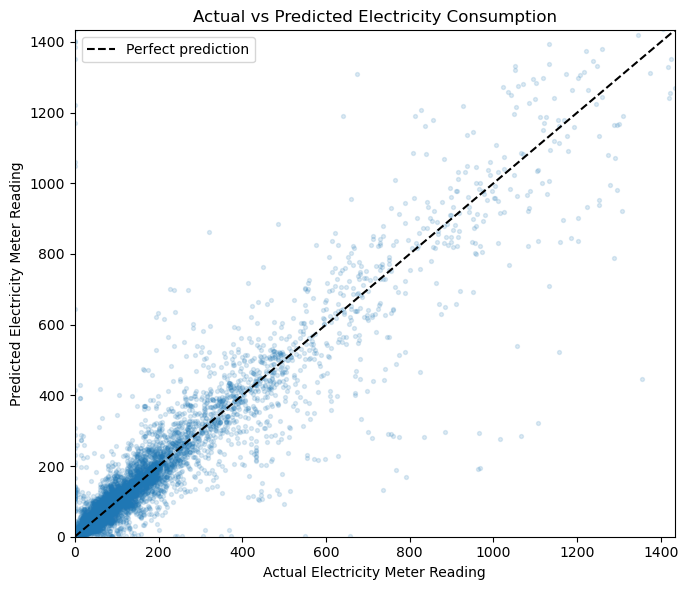

In [13]:
rng = np.random.default_rng(RANDOM_STATE)

sample_size = min(10000, len(test_df))

indices = rng.choice(
    len(test_df),
    size=sample_size,
    replace=False
)

actual = test_df[target].to_numpy()[indices]
predicted = test_pred[indices]

plt.figure(figsize=(7, 6))

plt.scatter(
    actual,
    predicted,
    alpha=0.15,
    s=8
)

limit = np.percentile(
    np.concatenate([actual, predicted]), 99
)

plt.plot(
    [0, limit],
    [0, limit],
    linestyle="--",
    color="black",
    linewidth=1.5,
    label="Perfect prediction"
)

plt.xlim(0, limit)
plt.ylim(0, limit)

plt.xlabel("Actual Electricity Meter Reading")
plt.ylabel("Predicted Electricity Meter Reading")
plt.title("Actual vs Predicted Electricity Consumption")

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "actual_vs_predicted_electricity_prediction.png",
    bbox_inches="tight"
)

plt.show()

## Save the model

In [14]:
model_file = MODEL_DIR / "electricity_lightgbm_full.joblib"

joblib.dump(
    {
        "model": final_model,
        "features": final_features,
        "model_name": selected_name,
        "parameters": model_params,
        "training_period": "2016-01 to 2016-09",
        "validation_period": "2016-10 to 2016-11",
        "test_period": "2016-12"
    },
    model_file
)

print("Model saved to:", model_file)

Model saved to: D:\Big Data Project\outputs\models\electricity_lightgbm_full.joblib
